# Customer churn prediction: a study of US telecom subscribers

*Exploratory data analysis, classification models, and error analysis*

**Dataset:** Cell2Cell, 51,047 historical customer records  
**Outcome:** churn (yes/no)  
**Approach:** data exploration, three classification baselines, validation-based selection, held-out testing

Which customers are most likely to leave a telecom provider, and how reliably can their risk be estimated? I examine the available customer data, compare predictive approaches, and look closely at the errors that would affect a retention campaign.

The study uses actual historical Cell2Cell records. Run `python -m churn.download` to obtain the source CSV before executing the notebook.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "churn").is_dir(): ROOT = ROOT.parent
assert (ROOT / "churn").is_dir(), "Open Jupyter from project root or notebooks/"
sys.path.insert(0, str(ROOT))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from churn.train import load_real_data, run, SEED
DATA = ROOT / "data" / "raw" / "cell2celltrain.csv"
X, y, sha = load_real_data(DATA)
print("Rows:",len(X),"Features:",X.shape[1],"SHA-256:",sha)
display(X.head())

Rows: 51047 Features: 56 SHA-256: 3f6b8ff0b8e8f5975aa0de9f1f54967e6c8cb867a9bec6cbb64f4c8990f9a645


,MonthlyRevenue,MonthlyMinutes,TotalRecurringCharge,DirectorAssistedCalls,OverageMinutes,RoamingCalls,PercChangeMinutes,PercChangeRevenues,DroppedCalls,BlockedCalls,...,ReferralsMadeBySubscriber,IncomeGroup,OwnsMotorcycle,AdjustmentsToCreditRating,HandsetPrice,MadeCallToRetentionTeam,CreditRating,PrizmCode,Occupation,MaritalStatus
0,24.00,219.0,22.0,0.25,0.0,0.0,-157.0,-19.0,0.7,0.7,...,0,4,No,0,30,Yes,1-Highest,Suburban,Professional,No
1,16.99,10.0,17.0,0.00,0.0,0.0,-4.0,0.0,0.3,0.0,...,0,5,No,0,30,No,4-Medium,Suburban,Professional,Yes
2,38.00,8.0,38.0,0.00,0.0,0.0,-2.0,0.0,0.0,0.0,...,0,6,No,0,Unknown,No,3-Good,Town,Crafts,Yes
3,82.28,1312.0,75.0,1.24,0.0,0.0,157.0,8.1,52.0,7.7,...,0,6,No,0,10,No,4-Medium,Other,Other,No
4,17.14,0.0,17.0,0.00,0.0,0.0,0.0,-0.2,0.0,0.0,...,0,9,No,1,10,No,1-Highest,Other,Professional,Yes


## Research questions

I start by examining churn prevalence, incomplete records, and the distribution of the customer attributes. I then compare how the attributes differ between customers who stayed and those who left.

The modeling questions are practical: does a classifier rank churners better than a simple prevalence baseline, how many genuine churners are identified, and how many customers would receive unnecessary retention outreach? The analysis is observational, so an association with churn does not mean an intervention would change that outcome.

In [2]:
# Customer-level data quality overview, including cardinality and null values
quality = pd.DataFrame({
    "dtype": X.dtypes.astype(str),
    "missing_n": X.isna().sum(),
    "missing_pct": (X.isna().mean()*100).round(2),
    "unique_values": X.nunique(dropna=True)
}).sort_values("missing_pct", ascending=False)
display(quality.head(30))
print("Duplicate feature rows:",int(X.duplicated().sum()),"of",len(X))
print("Outcome distribution:",y.value_counts().sort_index().to_dict())

,dtype,missing_n,missing_pct,unique_values
AgeHH1,float64,909,1.78,43
AgeHH2,float64,909,1.78,43
PercChangeMinutes,float64,367,0.72,2262
PercChangeRevenues,float64,367,0.72,2899
DirectorAssistedCalls,float64,156,0.31,146
TotalRecurringCharge,float64,156,0.31,214
MonthlyRevenue,float64,156,0.31,12665
MonthlyMinutes,float64,156,0.31,2719
RoamingCalls,float64,156,0.31,530
OverageMinutes,float64,156,0.31,746


Duplicate feature rows: 0 of 51047
Outcome distribution: {0: 36336, 1: 14711}


## 1. Dataset overview and missing values

The churn rate provides a reference point for evaluating model ranking. I also check missingness and duplicate records before examining the customer features.

Churn counts and percentages:


,count,percent
Churn,,
0,36336,71.18
1,14711,28.82


,missing_fraction
AgeHH1,0.017807
AgeHH2,0.017807
PercChangeMinutes,0.007189
PercChangeRevenues,0.007189
DirectorAssistedCalls,0.003056
TotalRecurringCharge,0.003056
MonthlyRevenue,0.003056
MonthlyMinutes,0.003056
RoamingCalls,0.003056
OverageMinutes,0.003056


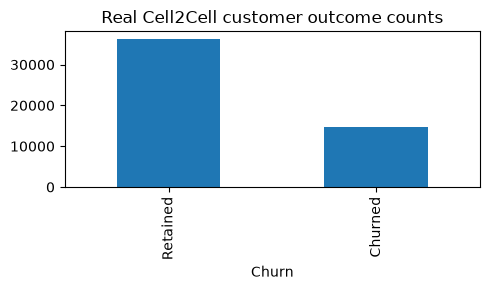

In [3]:
print("Churn counts and percentages:")
display(pd.DataFrame({"count":y.value_counts().sort_index(),"percent":(100*y.value_counts(normalize=True).sort_index()).round(2)}))
display(X.isna().mean().sort_values(ascending=False).head(15).rename("missing_fraction").to_frame())
fig, ax = plt.subplots(figsize=(5,3))
y.map({0:"Retained",1:"Churned"}).value_counts().plot.bar(ax=ax)
ax.set_title("Real Cell2Cell customer outcome counts")
plt.tight_layout(); plt.show()

## 2. Numeric customer characteristics

Usage and account variables can have long-tailed distributions. Histograms and summary statistics provide a clearer picture than averages alone.

,count,mean,std,min,25%,50%,75%,max
MonthlyRevenue,50891.0,58.834492,44.507336,-6.17,33.61,48.46,71.065,1223.38
MonthlyMinutes,50891.0,525.653416,529.871063,0.00,158.00,366.00,723.000,7359.00
TotalRecurringCharge,50891.0,46.830088,23.848871,-11.00,30.00,45.00,60.000,400.00
DirectorAssistedCalls,50891.0,0.895229,2.228546,0.00,0.00,0.25,0.990,159.39
OverageMinutes,50891.0,40.027785,96.588076,0.00,0.00,3.00,41.000,4321.00
RoamingCalls,50891.0,1.236244,9.818294,0.00,0.00,0.00,0.300,1112.40
PercChangeMinutes,50680.0,-11.547908,257.514772,-3875.00,-83.00,-5.00,66.000,5192.00
PercChangeRevenues,50680.0,-1.191985,39.574915,-1107.70,-7.10,-0.30,1.600,2483.50
DroppedCalls,51047.0,6.011489,9.043955,0.00,0.70,3.00,7.700,221.70
BlockedCalls,51047.0,4.085672,10.946905,0.00,0.00,1.00,3.700,384.30


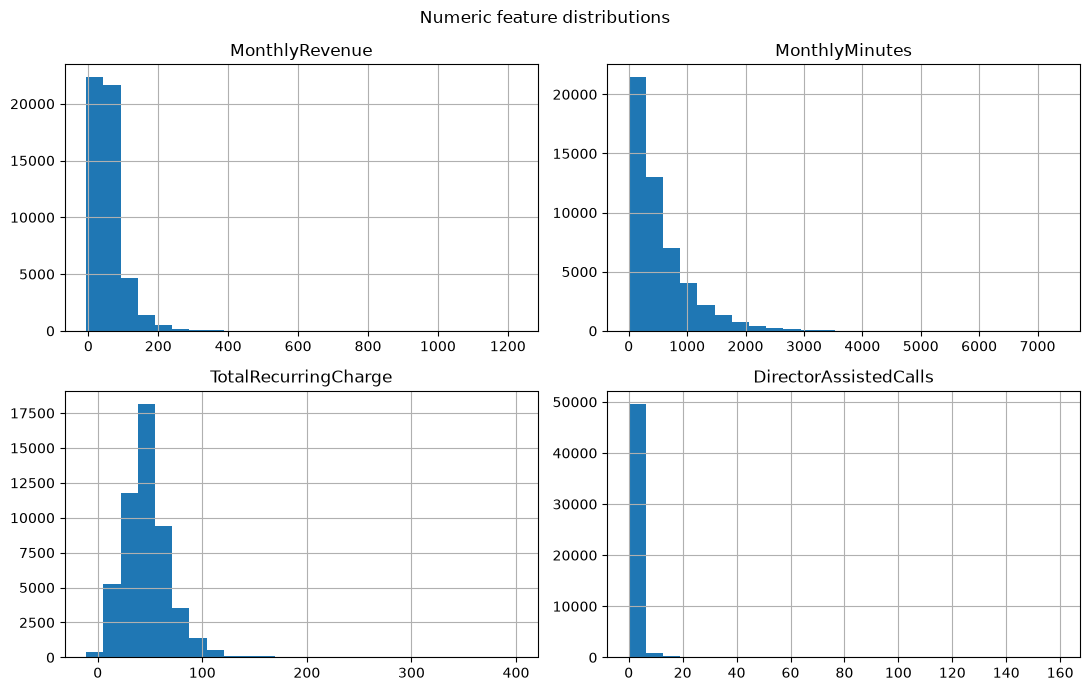

In [4]:
num_cols = X.select_dtypes(include="number").columns.tolist()
display(X[num_cols].describe().T.head(20))
if num_cols:
    ax = X[num_cols[:min(4,len(num_cols))]].hist(figsize=(11,7),bins=25)
    plt.suptitle("Numeric feature distributions"); plt.tight_layout(); plt.show()

### Numeric features and churn

These boxplots compare customers who churned with those who stayed. Group differences may be useful for prediction, though neither the plots nor the model establish causality.

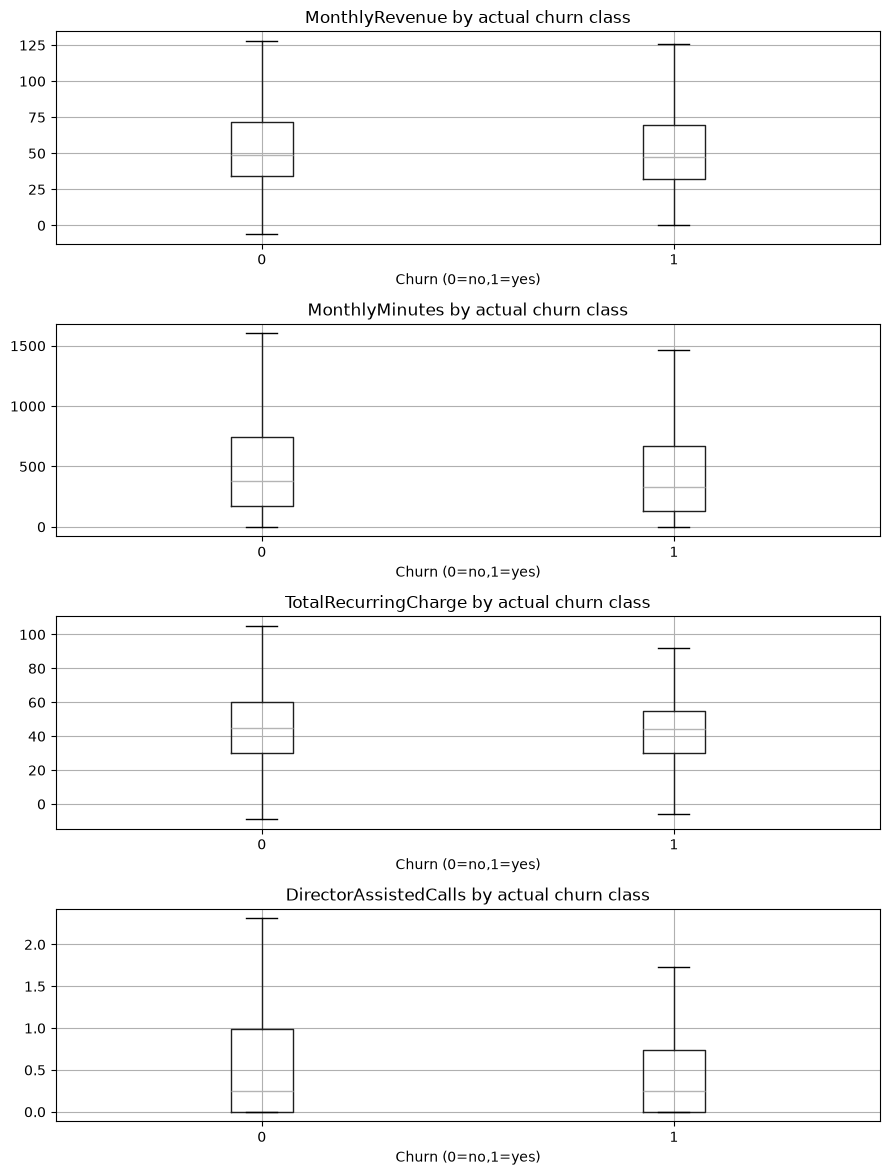

In [5]:
numeric = X.select_dtypes(include="number")
ranked = numeric.columns[numeric.notna().sum().gt(len(X)*0.75)].tolist()
if not ranked: raise ValueError("No well-observed numeric columns to plot")
fig, axes = plt.subplots(min(4,len(ranked)),1,figsize=(9,3*min(4,len(ranked))))
axes = np.atleast_1d(axes)
for ax, name in zip(axes,ranked[:4]):
    values = pd.DataFrame({"feature":numeric[name],"churn":y})
    values.boxplot(column="feature",by="churn",ax=ax,showfliers=False)
    ax.set_title(name+" by actual churn class");ax.set_xlabel("Churn (0=no,1=yes)")
plt.suptitle("");plt.tight_layout();plt.show()

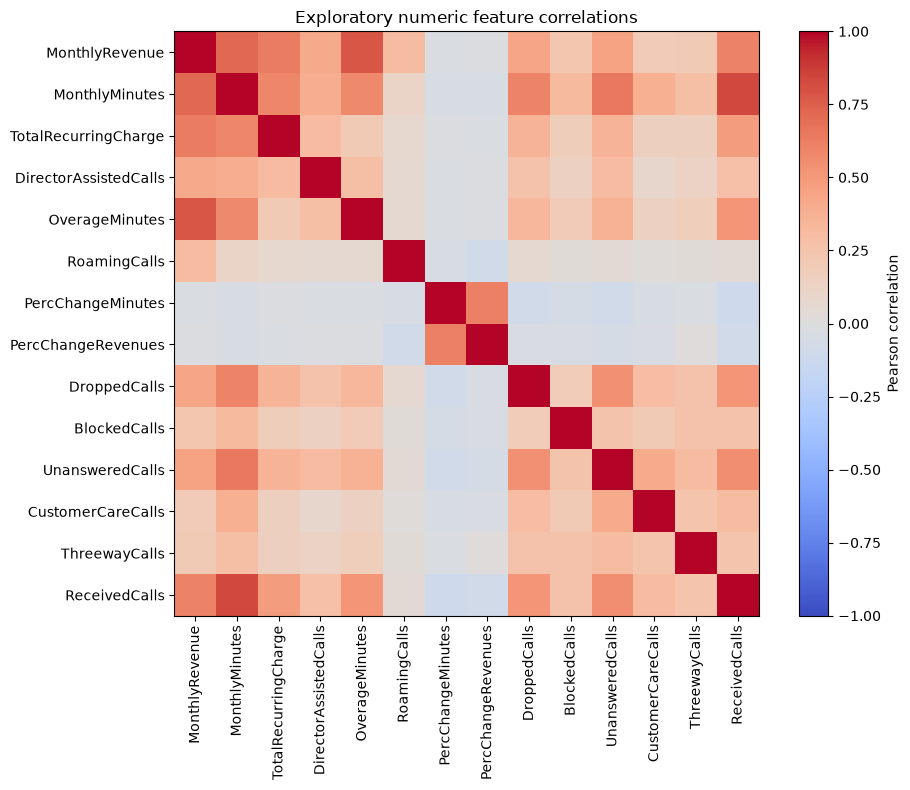

In [6]:
# Correlations describe association, not feature importance or causality.
corr = numeric.select_dtypes(include="number").corr(numeric_only=True)
selected = corr.columns[:min(14,len(corr))]
fig,ax=plt.subplots(figsize=(10,8))
matrix=corr.loc[selected,selected].to_numpy()
im=ax.imshow(matrix,interpolation="nearest",vmin=-1,vmax=1,cmap="coolwarm")
ax.set_xticks(range(len(selected)),selected,rotation=90)
ax.set_yticks(range(len(selected)),selected)
fig.colorbar(im,ax=ax,label="Pearson correlation")
ax.set_title("Exploratory numeric feature correlations")
plt.tight_layout();plt.show()

### Correlations among numeric features

The correlation matrix highlights attributes that move together. It is a descriptive check, not a measure of their independent contribution to predictions.

,churn_rate,customer_count
category,,
HOUHOU281,0.256291,1510
APCSIL301,0.261194,670
SANAUS512,0.271242,612
DALFTW817,0.273657,782
NYCBRO917,0.274347,1684
DALDAL214,0.274366,1498
NYCMAN917,0.276650,1182
APCFCH703,0.277139,783
SANSAN210,0.279006,724


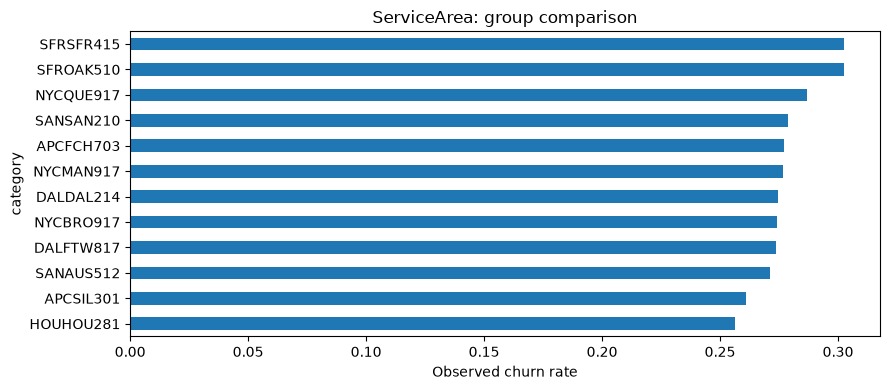

In [7]:
categories=X.select_dtypes(exclude="number").columns.tolist()
if categories:
    name=categories[0]
    table=pd.DataFrame({"category":X[name].astype("string").fillna("<missing>"),"churn":y})
    common=table["category"].value_counts().head(12).index
    group=table[table["category"].isin(common)].groupby("category")["churn"].agg(["mean","size"]).sort_values("mean")
    display(group.rename(columns={"mean":"churn_rate","size":"customer_count"}))
    fig,ax=plt.subplots(figsize=(9,4))
    group["mean"].plot.barh(ax=ax)
    ax.set_xlabel("Observed churn rate");ax.set_title(f"{name}: group comparison")
    plt.tight_layout();plt.show()
else:
    print("No categorical predictors in this dataset")

## 3. Categorical customer segments

Churn rates can vary across customer segments, but small groups are easy to overinterpret. I compare each group's churn rate alongside its sample size.

In [8]:
from churn.train import run
results = run(DATA, ROOT / "artifacts")
comparison = pd.DataFrame(results["validation"]).T
display(comparison[["average_precision","roc_auc","precision","recall","f1"]].sort_values("average_precision",ascending=False))
print("Winner:",results["selected_model"],"threshold:",round(results["threshold"],3))

,average_precision,roc_auc,precision,recall,f1
random_forest,0.4283,0.661908,0.363993,0.757308,0.491669
logistic_regression,0.378864,0.62204,0.336181,0.789259,0.47152
majority,0.288149,0.5,0.288149,1.0,0.447384


Winner: random_forest threshold: 0.44


## 4. Model comparison

Three approaches are compared: a prevalence-only baseline, logistic regression, and random forest. Imputation and encoding are fitted within training data. The model is selected using **validation average precision**, and its classification threshold is fixed using validation F1 before the test set is evaluated.

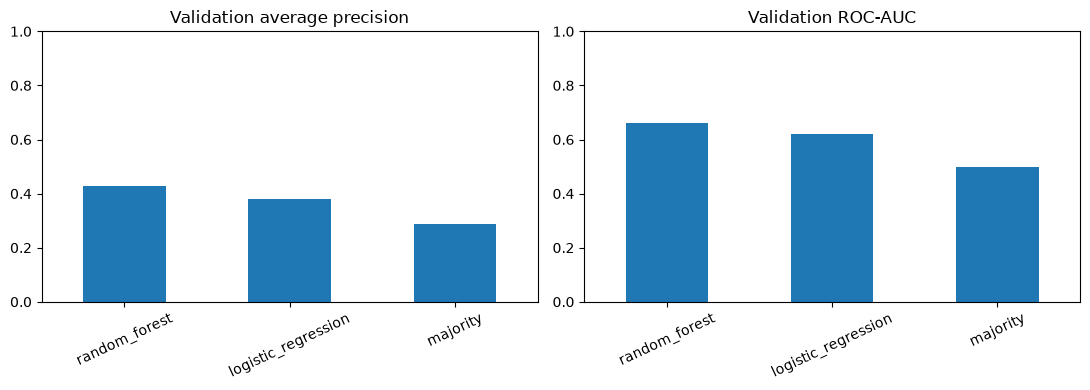

,average_precision,roc_auc,brier_score,precision,recall,f1
random_forest,0.4283,0.661908,0.219835,0.363993,0.757308,0.491669
logistic_regression,0.378864,0.62204,0.238424,0.336181,0.789259,0.47152
majority,0.288149,0.5,0.205119,0.288149,1.0,0.447384


In [9]:
validation = pd.DataFrame(results["validation"]).T.sort_values("average_precision",ascending=False)
fig,axes=plt.subplots(1,2,figsize=(11,4))
validation["average_precision"].plot.bar(ax=axes[0],title="Validation average precision")
validation["roc_auc"].plot.bar(ax=axes[1],title="Validation ROC-AUC")
for ax in axes: ax.set_ylim(0,1);ax.set_xlabel("");ax.tick_params(axis="x",rotation=25)
plt.tight_layout();plt.show()
display(validation[["average_precision","roc_auc","brier_score","precision","recall","f1"]])

### Why average precision?

Churners are the minority class. A model that predicts retention for everyone might appear accurate while identifying no churners. Average precision evaluates ranking over the precision–recall curve; ROC-AUC, precision, recall, and F1 provide additional perspectives.

,test
average_precision,0.425797
roc_auc,0.656335
brier_score,0.220860
precision,0.359512
recall,0.751530
f1,0.486362
balanced_accuracy,0.604782


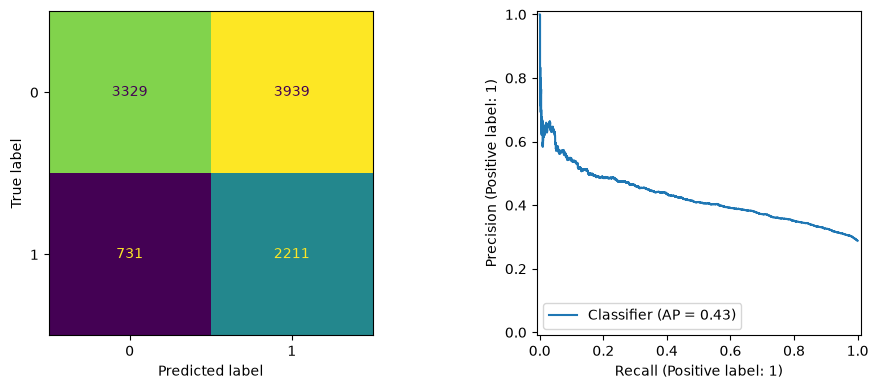

In [10]:
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay
from sklearn.metrics import precision_recall_curve, roc_curve
out = pd.read_csv(ROOT / "artifacts" / "test_predictions.csv")
display(pd.DataFrame([results["test"]]).drop(columns="confusion_matrix").T.rename(columns={0:"test"}))
from sklearn.metrics import confusion_matrix
fig,axes=plt.subplots(1,2,figsize=(10,4))
ConfusionMatrixDisplay.from_predictions(out["actual_churn"],out["predicted_churn"],ax=axes[0],colorbar=False)
PrecisionRecallDisplay.from_predictions(out["actual_churn"],out["churn_probability"],ax=axes[1])
plt.tight_layout();plt.show()

## 5. Held-out evaluation

The final test split contains customers unseen during training and selection. The confusion matrix shows correct classifications, missed churners, and false retention alerts. The precision–recall curve shows how those errors change across score thresholds.

,threshold,precision,recall,f1,flagged
0,0.10,0.288149,1.000000,0.447384,10210
1,0.15,0.288149,1.000000,0.447384,10210
2,0.20,0.288333,0.999660,0.447573,10200
3,0.25,0.292266,0.994222,0.451737,10008
4,0.30,0.303581,0.976886,0.463212,9467
5,0.35,0.315589,0.930999,0.471388,8679
6,0.40,0.338414,0.852821,0.484550,7414
7,0.45,0.366747,0.721278,0.486251,5786
8,0.50,0.409292,0.503059,0.451357,3616
9,0.55,0.483961,0.235894,0.317185,1434


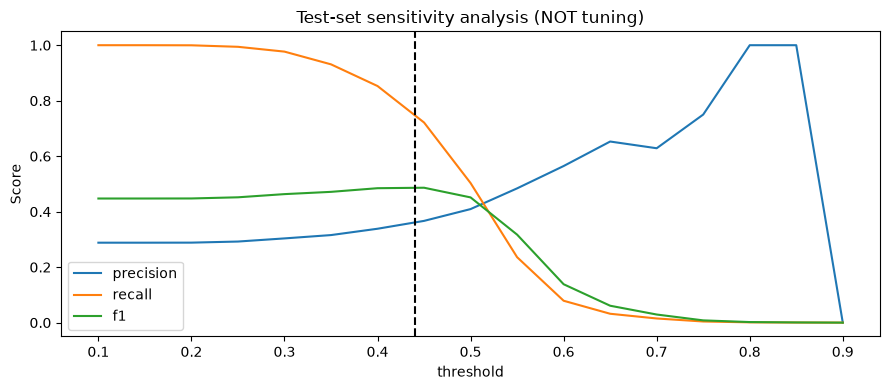

In [11]:
from sklearn.metrics import precision_score, recall_score, f1_score
diagnostic_thresholds=np.linspace(.1,.9,17)
rows=[]
for t in diagnostic_thresholds:
    p=(out["churn_probability"].to_numpy()>=t).astype(int)
    rows.append({"threshold":t,"precision":precision_score(out["actual_churn"],p,zero_division=0),
                 "recall":recall_score(out["actual_churn"],p,zero_division=0),
                 "f1":f1_score(out["actual_churn"],p,zero_division=0),
                 "flagged":int(p.sum())})
sensitivity=pd.DataFrame(rows)
display(sensitivity)
ax=sensitivity.plot(x="threshold",y=["precision","recall","f1"],figsize=(9,4))
ax.axvline(results["threshold"],ls="--",color="black",label="Frozen validation threshold")
ax.set_ylabel("Score");ax.set_title("Test-set sensitivity analysis (NOT tuning)")
plt.tight_layout();plt.show()

### What happens when the decision threshold changes?

A lower threshold typically catches more churners but flags more customers who would stay. The threshold sweep below is a **test-set diagnostic**, not an opportunity to tune the final model after looking at test outcomes.

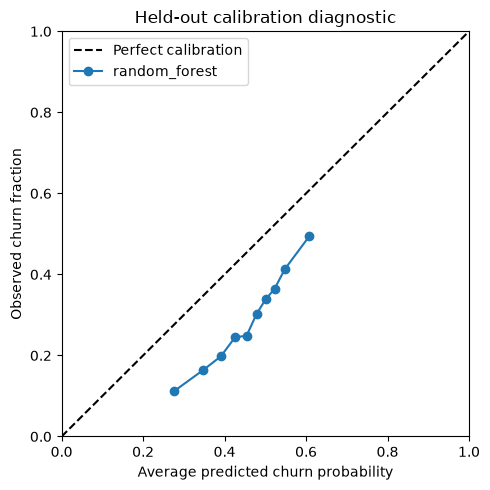

In [12]:
from sklearn.calibration import calibration_curve
fraction,mean_pred=calibration_curve(out["actual_churn"],out["churn_probability"],n_bins=10,strategy="quantile")
fig,ax=plt.subplots(figsize=(5,5))
ax.plot([0,1],[0,1],"k--",label="Perfect calibration")
ax.plot(mean_pred,fraction,"o-",label=results["selected_model"])
ax.set(xlabel="Average predicted churn probability",ylabel="Observed churn fraction",
       title="Held-out calibration diagnostic",xlim=(0,1),ylim=(0,1))
ax.legend();plt.tight_layout();plt.show()

### Probability calibration

A useful probability estimate should reflect observed churn frequency among similarly scored customers. I inspect calibration and Brier score separately from classification ranking.

In [13]:
report=out.copy()
report["error_type"]=np.select([
    (report.actual_churn==1)&(report.predicted_churn==0),
    (report.actual_churn==0)&(report.predicted_churn==1)],
    ["missed churner","false retention alert"],default="correct")
display(report["error_type"].value_counts().rename("customers").to_frame())
print("Dataset SHA256:",results["dataset_sha256"])
print("Best model:",results["selected_model"],"| Test AP:",round(results["test"]["average_precision"],4))
print("Conclusion: historical benchmark, not evidence of retention lift or production reliability.")

,customers
error_type,
correct,5540
false retention alert,3939
missed churner,731


Dataset SHA256: 3f6b8ff0b8e8f5975aa0de9f1f54967e6c8cb867a9bec6cbb64f4c8990f9a645
Best model: random_forest | Test AP: 0.4258
Conclusion: historical benchmark, not evidence of retention lift or production reliability.


## 6. Error analysis and conclusions

The selected random forest achieved **0.4258 average precision**, **0.6563 ROC-AUC**, **75.15% recall**, and **35.95% precision** on 10,210 held-out customers. It identified 2,211 of 2,942 churners but also flagged 3,939 customers who did not churn.

The model captures some signal, yet unnecessary outreach would be substantial. These historical results do not establish performance on future customers or the financial benefit of an intervention. Dataset provenance and full measured metrics are recorded in [the benchmark report](../docs/BENCHMARK.md).

### Further implementation

The repository also contains a separate software-engineering implementation with reusable model training, automated tests, and model artifacts.